# Assignment 1 — Data Exploration and Cleaning: Events

We explore the supplied `subsample_events.xml`, clean verified issues, link events to users and posts, and derive useful activity and time features.

The original files remain unchanged. Cleaned events retain their six original columns; reference mappings, quality flags, and summaries are exported separately.

**Requirements:** Python 3.10+, pandas 2.0+, NumPy, and Matplotlib. Set `DATA_DIR` and `ARFF_PATH`, then run the cells in order. This notebook uses the supplied sample, not the complete event database.


In [59]:
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("../../ProjectData")
ARFF_PATH = DATA_DIR / "additional_truths.arff"

OUTPUT_DIR = Path.cwd() / "output_events"
EVENTS_PATH = DATA_DIR / "subsample_events.xml"


## 1. XML structure and initial quality

Each row represents an event. We inspect all row structures while reading the XML once. Values are initially strings to preserve identifier and timestamp precision.


In [4]:
records = []
structures = Counter()
context = ET.iterparse(EVENTS_PATH, events=("start", "end"))
_, root = next(context)

for event, elem in context:
    if event == "end" and elem.tag == "row":
        structures[tuple(child.tag for child in elem)] += 1
        records.append({child.tag: child.text for child in elem})
        root.clear()

df_raw = pd.DataFrame(records, dtype="string")
del records, context, root, elem
original_columns = df_raw.columns.tolist()
assert original_columns == ["index", "event_id", "event_type", "truth_id", "user_id", "timestamp"]

print("Rows and columns:", df_raw.shape)
print("XML structures:", len(structures))
print("Fields:", original_columns)
display(df_raw.head())


Rows and columns: (716643, 6)
XML structures: 1
Fields: ['index', 'event_id', 'event_type', 'truth_id', 'user_id', 'timestamp']


,index,event_id,event_type,truth_id,user_id,timestamp
0,0,13564574,CR,2531,27,2022-04-28 17:29:00
1,1,14463475,CR,2778,177,2022-04-28 17:29:00
2,2,14473985,CR,3602,247,2022-04-28 17:29:00
3,3,14474918,CR,3687,251,2022-04-28 17:29:00
4,4,14492265,CR,3883,184,2022-04-28 17:29:00


In [5]:
baseline = pd.DataFrame({
    "Type": df_raw.dtypes.astype(str),
    "Null or blank": [df_raw[c].isna().sum() + df_raw[c].str.strip().eq("").sum() for c in df_raw],
    "Sentinel -1": [df_raw[c].str.strip().eq("-1").sum() for c in df_raw],
    "Distinct values": df_raw.nunique()
})
display(baseline)

df_clean = df_raw.copy()
for col in df_clean:
    df_clean[col] = df_clean[col].str.strip().replace("", pd.NA)

conversion_issues = []
for col in ["index", "event_id", "truth_id", "user_id"]:
    text = df_clean[col].str.replace(r"\.0+$", "", regex=True)
    valid = text.str.fullmatch(r"-?\d+", na=False)
    conversion_issues.append({"Column": col, "Invalid non-missing IDs": int((text.notna() & ~valid).sum())})
    assert (text.isna() | valid).all(), f"Inspect invalid {col} values."
    df_clean[col] = pd.to_numeric(text, errors="raise").astype("Int64")
display(pd.DataFrame(conversion_issues))


,Type,Null or blank,Sentinel -1,Distinct values
index,string,0,0,716643
event_id,string,0,0,716643
event_type,string,0,0,4
truth_id,string,0,0,65433
user_id,string,0,106949,26678
timestamp,string,0,0,714301


,Column,Invalid non-missing IDs
0,index,0
1,event_id,0
2,truth_id,0
3,user_id,0


## 2. Duplicates and identifier integrity

`event_id` identifies the event; `index` is retained as a source row identifier. We remove only identical event records, ignoring `index`, and stop if an event ID still has conflicting information.


In [7]:
event_columns = ["event_id", "event_type", "truth_id", "user_id", "timestamp"]
print("Exact source row duplicates:", df_raw.duplicated().sum())
print("Repeated index values:", df_clean["index"].duplicated().sum())
duplicate_events = df_clean.duplicated(event_columns)
removed_duplicates = int(duplicate_events.sum())
print("Identical events excluded:", removed_duplicates)

df_clean = df_clean.loc[~duplicate_events].reset_index(drop=True).copy()
conflicts = df_clean["event_id"].duplicated(keep=False)
display(df_clean.loc[conflicts].head(10))
assert not conflicts.any(), "Resolve conflicting event IDs before continuing."
assert df_clean["event_id"].notna().all() and df_clean["event_id"].gt(0).all()
assert df_clean["truth_id"].notna().all() and df_clean["truth_id"].gt(0).all()

features = df_clean[["event_id"]].copy()


Exact source row duplicates: 0
Repeated index values: 0
Identical events excluded: 0


,index,event_id,event_type,truth_id,user_id,timestamp


## 3. Missing users and user references

The sentinel `user_id = -1` becomes missing. The event remains usable for post-level activity counts, but not for identifying an actor.

Known user IDs are checked against `users.xml`. Missing actors are never replaced with the target post's author for likes, replies, or retruths.


In [9]:
features["user_id_was_unknown"] = df_clean["user_id"].eq(-1).fillna(False)
df_clean.loc[features["user_id_was_unknown"], "user_id"] = pd.NA
assert df_clean["user_id"].dropna().gt(0).all()

display(pd.crosstab(df_clean["event_type"], features["user_id_was_unknown"], margins=True))
print("Unknown actors:", df_clean["user_id"].isna().sum())

user_ids = []
context = ET.iterparse(DATA_DIR / "users.xml", events=("start", "end"))
_, root = next(context)
for event, elem in context:
    if event == "end" and elem.tag == "row":
        user_ids.append(int(elem.findtext("id_user")))
        root.clear()
assert len(user_ids) == len(set(user_ids))
user_ids = pd.Index(user_ids, dtype="int64")
del context, root, elem

features["user_reference_status"] = "matched"
features.loc[df_clean["user_id"].isna(), "user_reference_status"] = "unknown_actor"
absent_user = df_clean["user_id"].notna() & ~df_clean["user_id"].isin(user_ids)
features.loc[absent_user, "user_reference_status"] = "absent_from_users"
display(features["user_reference_status"].value_counts().to_frame("Events"))


user_id_was_unknown,False,True,All
event_type,,,
CR,2419,0,2419
LI,390470,68553,459023
REP,70933,12568,83501
RET,145872,25828,171700
All,609694,106949,716643


Unknown actors: 106949


,Events
user_reference_status,
matched,609694
unknown_actor,106949


## 4. Event types and time coverage

The observed codes are `CR` (creation), `LI` (like), `RET` (retruth), and `REP` (reply). Their frequencies describe the supplied sample, not platform-wide activity.

Source timestamps have no timezone label. We retain the recorded clock time without assigning UTC or converting to a local timezone. All subsequent time comparisons use this same recorded basis.


,Events,Percentage
event_type,,
LI,459023,64.05
RET,171700,23.96
REP,83501,11.65
CR,2419,0.34


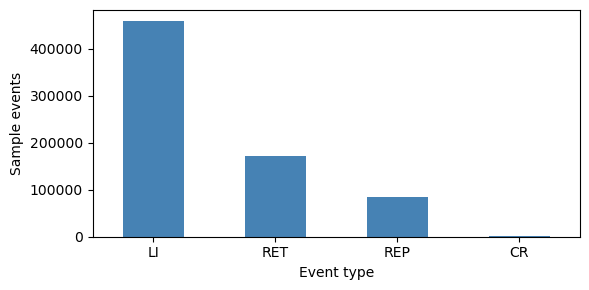

In [11]:
df_clean["event_type"] = df_clean["event_type"].str.upper()
valid_types = {"CR", "LI", "RET", "REP"}
assert df_clean["event_type"].isin(valid_types).all()

type_summary = df_clean["event_type"].value_counts().to_frame("Events")
type_summary["Percentage"] = (type_summary["Events"] / len(df_clean) * 100).round(2)
display(type_summary)
type_summary["Events"].plot.bar(figsize=(6, 3), color="steelblue", rot=0)
plt.ylabel("Sample events")
plt.xlabel("Event type")
plt.tight_layout()
plt.show()


First event: 2022-02-14 00:00:00
Last event: 2026-09-20 13:59:59.999999
Chronologically sorted: False


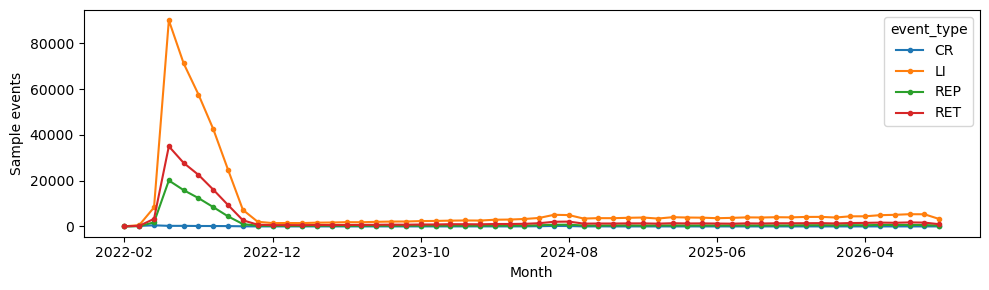

In [12]:
timestamp_raw = df_clean["timestamp"].copy()
df_clean["timestamp"] = pd.to_datetime(timestamp_raw, format="ISO8601", errors="raise")
assert df_clean["timestamp"].dt.tz is None
assert df_clean["timestamp"].notna().all()

print("First event:", df_clean["timestamp"].min())
print("Last event:", df_clean["timestamp"].max())
print("Chronologically sorted:", df_clean["timestamp"].is_monotonic_increasing)

month = df_clean["timestamp"].dt.to_period("M")
monthly_events = pd.crosstab(month, df_clean["event_type"])
full_months = pd.period_range(month.min(), month.max(), freq="M")
monthly_events = monthly_events.reindex(full_months, fill_value=0)
monthly_events.index = monthly_events.index.astype(str)
monthly_events.plot(figsize=(10, 3), marker=".")
plt.xlabel("Month")
plt.ylabel("Sample events")
plt.tight_layout()
plt.show()


In [13]:
features["timestamp_date_only"] = timestamp_raw.str.fullmatch(r"\d{4}-\d{2}-\d{2}", na=False)
features["timestamp_at_midnight"] = df_clean["timestamp"].eq(df_clean["timestamp"].dt.normalize())
features["timestamp_at_day_end"] = (
    df_clean["timestamp"].dt.hour.eq(23)
    & df_clean["timestamp"].dt.minute.eq(59)
    & df_clean["timestamp"].dt.second.eq(59)
)
reference_date = pd.Timestamp("2026-11-11")
features["timestamp_after_reference_date"] = df_clean["timestamp"].ge(reference_date + pd.Timedelta(days=1))
display(features[["timestamp_date_only", "timestamp_at_midnight", "timestamp_at_day_end", "timestamp_after_reference_date"]].sum().to_frame("Events"))
display(pd.crosstab(df_clean["event_type"], features["timestamp_at_day_end"]))


,Events
timestamp_date_only,0
timestamp_at_midnight,426
timestamp_at_day_end,1574
timestamp_after_reference_date,0


timestamp_at_day_end,False,True
event_type,,
CR,2314,105
LI,458180,843
REP,83317,184
RET,171258,442


Repeated midnight or end-of-day times may reflect limited precision or collection conventions. They are indicators for review, not grounds for changing timestamps. We do not discard early events using an assumed platform launch date.

## 5. Additional post references from ARFF

Some events refer to the large external post IDs in `additional_truths.arff`, rather than the internal IDs in `truths.csv`. Identifiers are read as exact strings; they must not pass through floating-point conversion.

We need only reference metadata, not post text. In this supplied ARFF, each record occupies one physical line. We verify the header order and read only the two leading fields and three trailing fields, which contain no embedded commas. This is a reader for this source layout, not a general ARFF parser.


In [15]:
attributes = []
arff_records = []
in_data = False
with ARFF_PATH.open(encoding="utf-8-sig") as file:
    for line in file:
        line = line.strip()
        if not line or line.startswith("%"):
            continue
        if not in_data:
            if line.lower().startswith("@attribute"):
                attributes.append(line.split()[1].strip("'\""))
            in_data = line.lower() == "@data"
            continue
        leading = line.split(",", 2)
        trailing = line.rsplit(",", 3)
        assert len(leading) == 3 and len(trailing) == 4
        post_id = leading[0].strip()
        timestamp = leading[1].strip("'\"")
        external_id, author, scraped = [s.strip().strip("'\"") for s in trailing[1:]]
        assert post_id.isdecimal() and external_id.isdecimal()
        arff_records.append((post_id, external_id, timestamp, author))

assert attributes == ["id", "timestamp", "text", "url", "reply_count", "retruth_count", "like_count", "external_id", "author", "time_scraped"]
arff = pd.DataFrame(arff_records, columns=["source_id", "external_id", "timestamp", "author"], dtype="string")
del arff_records
assert arff["source_id"].is_unique
assert arff["source_id"].eq(arff["external_id"]).all()
arff["timestamp"] = pd.to_datetime(arff["timestamp"], format="ISO8601", errors="raise")
arff["author"] = pd.to_numeric(arff["author"].str.replace(r"\.0+$", "", regex=True), errors="raise").astype("Int64")
print("Additional post references:", len(arff))
display(arff.head())


Additional post references: 35222


,source_id,external_id,timestamp,author
0,117323511508375196,117323511508375196,2026-09-24 01:51:54,27
1,117323155721195611,117323155721195611,2026-09-24 00:21:25,27
2,117323148147220269,117323148147220269,2026-09-24 00:19:29,27
3,117322092055919832,117322092055919832,2026-09-23 19:50:55,27
4,117322065119445871,117322065119445871,2026-09-23 19:44:04,27


## 6. Main-corpus references and cross-source identity

We read `truths.csv` in blocks and retain only metadata needed by these events or by ARFF overlap checks. Repeated internal IDs are summarized conservatively: author disagreements remain unresolved, and all reported post timestamps contribute to the reference range.

Numeric external IDs can also be recovered from post URLs. If the external ID and URL disagree, neither is selected automatically for cross-source matching.


In [17]:
event_truth_keys = df_clean["truth_id"].astype("string")
needed_ids = set(event_truth_keys)
arff_external_ids = set(arff["external_id"])
main_parts = []
main_id_set = set()
main_rows = 0
external_conflicts = 0

for chunk in pd.read_csv(DATA_DIR / "truths.csv", usecols=["id", "external_id", "url", "author", "timestamp"], dtype="string", keep_default_na=False, chunksize=100000):
    chunk["id"] = chunk["id"].str.strip().str.replace(r"\.0+$", "", regex=True)
    assert chunk["id"].str.fullmatch(r"\d+", na=False).all()
    main_id_set.update(chunk["id"])
    main_rows += len(chunk)
    external = chunk["external_id"].str.strip()
    external = external.where(external.str.fullmatch(r"\d+", na=False))
    url_id = chunk["url"].str.extract(r"(?i)^https?://(?:www\.)?truthsocial\.com/@[^/?#]+/posts/(\d+)/?$", expand=False)
    numeric_url = chunk["url"].where(chunk["url"].str.fullmatch(r"\d+", na=False))
    url_id = url_id.combine_first(numeric_url)
    disagreement = external.notna() & url_id.notna() & external.ne(url_id).fillna(False)
    external_conflicts += int(disagreement.sum())
    chunk["external_key"] = external.combine_first(url_id).mask(disagreement)
    keep = chunk["id"].isin(needed_ids) | chunk["external_key"].isin(arff_external_ids)
    main_parts.append(chunk.loc[keep, ["id", "external_key", "author", "timestamp"]].copy())

main = pd.concat(main_parts, ignore_index=True).drop_duplicates()
del main_parts, chunk
main["author"] = pd.to_numeric(main["author"].str.replace(r"\.0+$", "", regex=True).replace("", pd.NA), errors="raise").astype("Int64")
main["timestamp"] = pd.to_datetime(main["timestamp"], format="ISO8601", errors="raise")
print("Main-corpus rows scanned:", main_rows)
print("Distinct main-corpus IDs:", len(main_id_set))
print("External ID / URL disagreements:", external_conflicts)
print("Distinct relevant metadata rows:", len(main))


Main-corpus rows scanned: 1051149
Distinct main-corpus IDs: 1038821
External ID / URL disagreements: 94
Distinct relevant metadata rows: 36663


In [18]:
main_ref = main.groupby("id").agg(
    post_time_min=("timestamp", "min"), post_time_max=("timestamp", "max"),
    distinct_post_times=("timestamp", "nunique"),
    author_id=("author", "first"), distinct_authors=("author", "nunique")
)
main_ref["author_id"] = main_ref["author_id"].where(main_ref["distinct_authors"].eq(1))
main_ref["post_key"] = "main:" + main_ref.index.astype("string")
print("Referenced main IDs with multiple reported times:", main_ref["distinct_post_times"].gt(1).sum())
print("Referenced main IDs with conflicting authors:", main_ref["distinct_authors"].gt(1).sum())

external_pairs = main[["external_key", "id"]].dropna().drop_duplicates()
external_counts = external_pairs.groupby("external_key")["id"].nunique()
unique_external = external_counts[external_counts == 1].index
external_lookup = external_pairs.loc[external_pairs["external_key"].isin(unique_external)].set_index("external_key")["id"]

arff["main_candidate_id"] = arff["external_id"].map(external_lookup)
candidate_author = arff["main_candidate_id"].map(main_ref["author_id"])
same_author = arff["author"].eq(candidate_author).fillna(False)
shared_unique = arff["main_candidate_id"].notna() & same_author
arff["post_key"] = "arff:" + arff["source_id"]
arff.loc[shared_unique, "post_key"] = "main:" + arff.loc[shared_unique, "main_candidate_id"]
arff["identity_status"] = "additional_source"
overlap = arff["external_id"].isin(external_counts.index)
arff.loc[overlap, "identity_status"] = "overlap_unresolved"
arff.loc[shared_unique, "identity_status"] = "shared_external_id_and_author"
display(arff["identity_status"].value_counts().to_frame("Posts"))
display(arff.loc[arff["identity_status"].eq("overlap_unresolved"), ["source_id", "main_candidate_id", "author", "identity_status"]].head(10))


Referenced main IDs with multiple reported times: 0
Referenced main IDs with conflicting authors: 0


,Posts
identity_status,
additional_source,35190
shared_external_id_and_author,29
overlap_unresolved,3


,source_id,main_candidate_id,author,identity_status
15094,113008796172112928,<NA>,27,overlap_unresolved
34591,109027164115408705,<NA>,27,overlap_unresolved
34617,109017355982286163,<NA>,27,overlap_unresolved


A unique external ID and matching author support a shared post identity. Other overlaps remain separate source records with an explicit warning; we do not select the smallest internal ID or assume that repeated external IDs identify one internal record.

`post_key` records the source namespace (`main:` or `arff:`), unless a validated cross-source match links it to a main record. These keys support this notebook's reference analysis; they are not a replacement for the main corpus's warehouse key mapping.


In [20]:
arff_lookup = arff.set_index("source_id")
main_match = event_truth_keys.isin(main_id_set)
arff_match = event_truth_keys.isin(arff_lookup.index)
main_key = "main:" + event_truth_keys
arff_key = event_truth_keys.map(arff_lookup["post_key"])
namespace_conflict = main_match & arff_match & main_key.ne(arff_key).fillna(False)

features["post_reference_status"] = "unresolved"
features["post_key"] = pd.Series(pd.NA, index=df_clean.index, dtype="string")
features.loc[main_match, "post_reference_status"] = "main"
features.loc[main_match, "post_key"] = main_key[main_match]
use_arff = ~main_match & arff_match
features.loc[use_arff, "post_reference_status"] = "arff"
features.loc[use_arff, "post_key"] = arff_key[use_arff]
features.loc[namespace_conflict, "post_reference_status"] = "namespace_conflict"
features.loc[namespace_conflict, "post_key"] = pd.NA
features["post_identity_overlap_unresolved"] = (
    use_arff & event_truth_keys.map(arff_lookup["identity_status"]).eq("overlap_unresolved").fillna(False)
)
display(features["post_reference_status"].value_counts().to_frame("Events"))
print("Events with unresolved cross-source identity:", features["post_identity_overlap_unresolved"].sum())


,Events
post_reference_status,
main,483785
arff,232858


Events with unresolved cross-source identity: 7


In [21]:
# Use the metadata from the source that actually supplied each reference.
post_time_min = event_truth_keys.map(main_ref["post_time_min"]).where(main_match & ~namespace_conflict)
post_time_max = event_truth_keys.map(main_ref["post_time_max"]).where(main_match & ~namespace_conflict)
post_author = event_truth_keys.map(main_ref["author_id"]).where(main_match & ~namespace_conflict)
post_time_min.loc[use_arff] = event_truth_keys[use_arff].map(arff_lookup["timestamp"])
post_time_max.loc[use_arff] = post_time_min[use_arff]
post_author.loc[use_arff] = event_truth_keys[use_arff].map(arff_lookup["author"])

# Persist a compact reference table for all source IDs used by the sample.
post_reference = pd.DataFrame({
    "source_truth_id": event_truth_keys,
    "reference_source": features["post_reference_status"],
    "post_key": features["post_key"],
    "post_time_min": post_time_min, "post_time_max": post_time_max,
    "post_author_id": post_author
}).drop_duplicates()
assert not post_reference.duplicated(["reference_source", "source_truth_id"]).any()
print("Distinct post references:", len(post_reference))


Distinct post references: 65433


## 7. Recovery checks for unknown actors

For creation events only, the post author can provide an actor candidate when that author is unambiguous and exists in `users.xml`. Known creation events are compared first; disagreements stop automatic recovery.

A quote's author is not the actor of an event merely because the event targets that quoted post. We inspect this join as a diagnostic and do not use it to fill likes, replies, or retruths.


In [23]:
creation_event = df_clean["event_type"].eq("CR")
comparable_creation = creation_event & df_clean["user_id"].notna() & post_author.notna()
creation_actor_conflict = comparable_creation & df_clean["user_id"].ne(post_author).fillna(False)
print("Comparable known creation actors:", comparable_creation.sum())
print("Creation actor / post author disagreements:", creation_actor_conflict.sum())

recoverable_creation = creation_event & df_clean["user_id"].isna() & post_author.isin(user_ids)
features["user_id_recovered"] = False
if not creation_actor_conflict.any():
    df_clean.loc[recoverable_creation, "user_id"] = post_author[recoverable_creation].astype("Int64")
    features.loc[recoverable_creation, "user_id_recovered"] = True
    features.loc[recoverable_creation, "user_reference_status"] = "recovered_from_creation_author"
print("Creation actors recovered:", features["user_id_recovered"].sum())
print("Actors still unknown:", df_clean["user_id"].isna().sum())


Comparable known creation actors: 2419
Creation actor / post author disagreements: 0
Creation actors recovered: 0
Actors still unknown: 106949


In [24]:
quotes = pd.read_json(DATA_DIR / "quotes.json")
for col in ["quoting_truth", "quoting_user"]:
    quotes[col] = pd.to_numeric(quotes[col], errors="raise").astype("Int64")
quoting_users = quotes.groupby("quoting_truth")["quoting_user"].nunique()
quote_candidate = df_clean["truth_id"].map(quoting_users)
quote_match = df_clean["user_id"].isna() & main_match & quote_candidate.notna()
print("Unknown-actor events whose target appears as quoting_truth:", quote_match.sum())
display(df_clean.loc[quote_match, "event_type"].value_counts().to_frame("Events"))
print("No actors recovered from this target-post join.")
del quotes


Unknown-actor events whose target appears as quoting_truth: 192


,Events
event_type,
LI,129
RET,44
REP,19


No actors recovered from this target-post join.


## 8. Event–post chronology

We compare each event with its source post's full reported timestamp range. Events before all reported post times are flagged, while times between conflicting post timestamps remain ambiguous.

A chronological flag reports a disagreement in the supplied timestamps. It does not prove which timestamp is wrong. Midnight and end-of-day patterns are examined separately; no artificial time shifts are applied.


In [26]:
features["temporal_status"] = "no_reported_precedence_issue"
missing_post_time = post_time_min.isna() | post_time_max.isna()
before_post = df_clean["timestamp"].lt(post_time_min)
ambiguous_post_time = df_clean["timestamp"].ge(post_time_min) & df_clean["timestamp"].lt(post_time_max)
features.loc[missing_post_time, "temporal_status"] = "post_timestamp_unavailable"
features.loc[ambiguous_post_time, "temporal_status"] = "ambiguous_post_timestamps"
features.loc[before_post, "temporal_status"] = "event_before_reported_post"
features["seconds_since_reported_post"] = (
    (df_clean["timestamp"] - post_time_min).dt.total_seconds()
    .where(~missing_post_time & post_time_min.eq(post_time_max))
)

display(pd.crosstab(features["post_reference_status"], features["temporal_status"]))
anomalies = df_clean.loc[before_post, ["event_id", "event_type", "truth_id", "timestamp"]].copy()
anomalies["post_time_min"] = post_time_min[before_post]
anomalies["event_at_day_end"] = features.loc[before_post, "timestamp_at_day_end"]
print("Events before all reported post times:", len(anomalies))
display(anomalies.head(10))
display(pd.crosstab(features.loc[before_post, "post_reference_status"], features.loc[before_post, "timestamp_at_day_end"]))


temporal_status,event_before_reported_post,no_reported_precedence_issue
post_reference_status,,
arff,280,232578
main,1567,482218


Events before all reported post times: 1847


,event_id,event_type,truth_id,timestamp,post_time_min,event_at_day_end
455632,35579087,LI,1269331,2024-07-07 23:59:59.999999,2024-07-08 17:47:00,True
455653,37881283,CR,1966248,2024-08-23 23:59:59.999999,2024-08-24 02:38:00,True
455654,36676055,LI,1558108,2024-07-26 23:59:59.999999,2024-07-27 12:22:00,True
455876,39312572,LI,2339153,2024-09-01 23:59:59.999999,2024-09-02 00:18:00,True
455927,35315540,LI,1173719,2024-06-24 23:59:59.999999,2024-06-25 02:18:00,True
456104,35951189,RET,1378206,2024-07-13 23:59:59.999999,2024-07-14 01:47:00,True
456237,38904691,LI,2248154,2024-08-06 23:59:59.999999,2024-08-07 00:17:00,True
456424,39579707,LI,117307255154500060,2026-09-20 13:59:59.999999,2026-09-21 04:57:41,False
456619,35384578,LI,1203017,2024-06-27 23:59:59.999999,2024-06-28 13:21:00,True
456637,35930490,LI,1372146,2024-07-13 23:59:59.999999,2024-07-14 15:10:00,True


timestamp_at_day_end,False,True
post_reference_status,,
arff,280,0
main,0,1567


`seconds_since_reported_post` is a signed difference between reported values, not a validated response-time measurement. Use the temporal status and timestamp-precision flags before interpreting it.

## 9. Activity, concentration, and outliers

Activity summaries count distinct sample events. Unknown users are excluded from user rankings. Events remain included in post-level counts when their post reference is resolved.

Large activity counts are statistical outliers, not automatic errors. We retain them and inspect event types and the concentration of activity.


In [28]:
events_per_user = df_clean.groupby("user_id")["event_id"].nunique()
activity = df_clean[["event_id", "event_type", "user_id", "timestamp"]].copy()
activity["post_key"] = features["post_key"]
events_per_post = activity.groupby("post_key")["event_id"].nunique()
display(pd.DataFrame({
    "Events per known user": events_per_user.describe(percentiles=[.5, .9, .95, .99]),
    "Events per resolved post": events_per_post.describe(percentiles=[.5, .9, .95, .99])
}).round(2))
display(events_per_user.nlargest(10).rename("Sample events").to_frame())

outlier_summary = []
for label, counts in [("known_user", events_per_user), ("resolved_post", events_per_post)]:
    q1, q3 = counts.quantile([.25, .75])
    upper = q3 + 1.5 * (q3 - q1)
    outlier_ids = counts[counts > upper].index
    features[label + "_activity_outlier"] = (
        df_clean["user_id"].isin(outlier_ids) if label == "known_user"
        else features["post_key"].isin(outlier_ids)
    )
    outlier_summary.append({"Group": label, "IQR upper bound": upper, "Groups above bound": len(outlier_ids)})
display(pd.DataFrame(outlier_summary))


,Events per known user,Events per resolved post
count,26677.00,65408.00
mean,22.85,10.96
std,514.14,592.71
min,1.00,1.00
50%,1.00,2.00
90%,5.00,10.00
95%,16.00,12.00
99%,218.00,19.00
max,50090.00,50661.00


,Sample events
user_id,
12967,50090
4273,30581
27,24501
230747,20394
12524,17551
438,16112
11363,15974
5881,13710
8256,12728


,Group,IQR upper bound,Groups above bound
0,known_user,3.5,3428
1,resolved_post,13.5,2423


,sample_events,known_actors,first_event,last_event,CR,LI,REP,RET
post_key,,,,,,,,
main:125307,50661,3004,2022-04-28 17:29:00.000000000,2022-09-27 23:33:41.318885822,1,31340,7137,12183
main:130407,50661,3016,2022-04-28 17:29:00.000000000,2022-09-28 00:08:33.929018738,1,31340,7137,12183
main:366255,50661,2907,2022-04-28 17:29:00.000000000,2022-10-12 05:19:13.086723164,1,31340,7137,12183
main:366931,50661,2819,2022-04-28 17:29:00.000000000,2022-10-11 20:30:51.366130222,1,31340,7137,12183
main:413805,50661,2962,2022-04-28 17:29:00.000000000,2022-10-13 06:11:40.932804668,1,31340,7137,12183
main:424756,50661,2806,2022-04-28 17:29:00.000000000,2022-10-14 12:53:46.204487602,1,31340,7137,12183
main:510621,50661,3012,2022-04-28 17:29:00.000000000,2022-10-17 18:54:09.729392960,1,31340,7137,12183
main:69023,50661,3124,2022-04-28 17:29:00.000000000,2022-09-22 03:11:40.608470840,1,31340,7137,12183
arff:108211822140637685,49509,4980,2022-04-28 21:29:28.000000000,2026-09-09 09:37:58.001953496,1,30969,6723,11816


Share of resolved-post events on the top 10 posts (%): 63.47


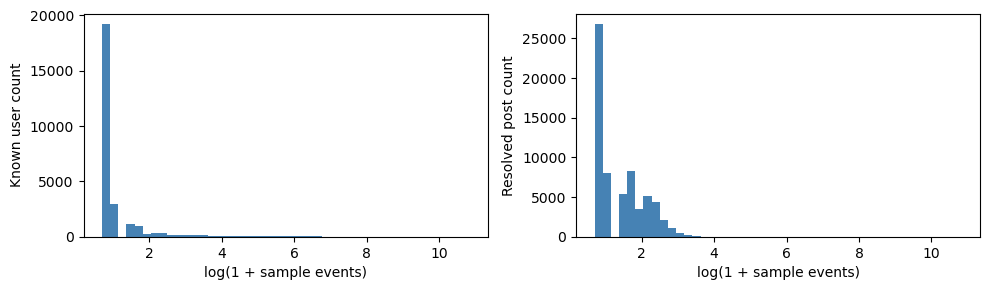

In [29]:
top_post_keys = events_per_post.nlargest(10).index
top_activity = activity.loc[activity["post_key"].isin(top_post_keys)]
top_posts = top_activity.groupby("post_key").agg(
    sample_events=("event_id", "nunique"), known_actors=("user_id", "nunique"),
    first_event=("timestamp", "min"), last_event=("timestamp", "max")
).join(pd.crosstab(top_activity["post_key"], top_activity["event_type"]))
display(top_posts.sort_values("sample_events", ascending=False))
print("Share of resolved-post events on the top 10 posts (%):",
      round(events_per_post.nlargest(10).sum() / events_per_post.sum() * 100, 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, counts, label in zip(axes, [events_per_user, events_per_post], ["Known user", "Resolved post"]):
    ax.hist(np.log1p(counts), bins=45, color="steelblue")
    ax.set_xlabel("log(1 + sample events)")
    ax.set_ylabel(label + " count")
plt.tight_layout()
plt.show()
del activity, top_activity


## 10. Creation coverage and time features

A post without a `CR` event in the sample is not necessarily missing its creation event in the full dataset. Multiple `CR` records for one resolved post are reported for review, not silently collapsed.

Calendar features and day/night bands use the recorded clock. Night is 20:00–07:59, day is 08:00–19:59. Time bands are left missing for date-only or end-of-day timestamps whose apparent hour could be a collection convention.


In [31]:
creation_counts = features.loc[creation_event & features["post_key"].notna(), "post_key"].value_counts()
features["post_has_sample_creation"] = features["post_key"].isin(creation_counts.index)
features["post_has_multiple_creations"] = features["post_key"].isin(creation_counts[creation_counts > 1].index)
print("Resolved posts:", len(events_per_post))
print("Posts with CR in the sample:", len(creation_counts))
print("Posts with multiple CR events:", creation_counts.gt(1).sum())
display(creation_counts[creation_counts > 1].head(10).rename("Creation events").to_frame())

features["year"] = df_clean["timestamp"].dt.year.astype("Int64")
features["month"] = df_clean["timestamp"].dt.strftime("%Y-%m").astype("string")
features["hour_recorded"] = df_clean["timestamp"].dt.hour.astype("Int64")
features["weekday_recorded"] = df_clean["timestamp"].dt.day_of_week.astype("Int64")
features["time_band"] = pd.Series(pd.NA, index=df_clean.index, dtype="string")
usable_clock = ~features["timestamp_date_only"] & ~features["timestamp_at_day_end"]
night = features["hour_recorded"].ge(20) | features["hour_recorded"].lt(8)
features.loc[usable_clock & night, "time_band"] = "night"
features.loc[usable_clock & ~night, "time_band"] = "day"
display(features["time_band"].value_counts(dropna=False).to_frame("Events"))


Resolved posts: 65408
Posts with CR in the sample: 2419
Posts with multiple CR events: 0


,Creation events
post_key,


,Events
time_band,
night,358014
day,357055
<NA>,1574


## 11. Validation and exports

The clean file preserves original post IDs and all non-duplicate events. Source-qualified post keys and mapping status belong to the integrated file; quality indicators and time features belong to the feature file.

The reference table includes only post metadata needed by this sample. This is an event-to-post reference integration, not an export of the complete ARFF-enriched post-text corpus.


In [33]:
df_final = df_clean[original_columns].copy()
assert len(df_final) == len(df_raw) - removed_duplicates
assert df_final["event_id"].notna().all() and df_final["event_id"].is_unique
assert df_final["event_type"].isin(valid_types).all()
assert df_final["timestamp"].notna().all()
assert df_final["user_id"].dropna().isin(user_ids).all()
assert features["event_id"].tolist() == df_final["event_id"].tolist()
assert features["post_key"].dropna().isin(post_reference["post_key"].dropna()).all()
assert not features["user_id_was_unknown"].loc[features["user_id_recovered"]].eq(False).any()

# Compare preserved known actors and timestamps against the original strings.
original_events = df_raw.drop_duplicates(event_columns).reset_index(drop=True)
original_actors = pd.to_numeric(original_events["user_id"], errors="raise").astype("Int64")
known_original = original_actors.gt(0)
assert df_final.loc[known_original, "user_id"].equals(original_actors[known_original])
assert df_final["timestamp"].equals(pd.to_datetime(original_events["timestamp"], format="ISO8601", errors="raise"))
assert df_final["truth_id"].equals(pd.to_numeric(original_events["truth_id"], errors="raise").astype("Int64"))

validation_summary = pd.Series({
    "Original rows": len(df_raw), "Cleaned rows": len(df_final),
    "Identical events removed": removed_duplicates,
    "Unknown actors remaining": int(df_final["user_id"].isna().sum()),
    "Recovered creation actors": int(features["user_id_recovered"].sum()),
    "Unresolved post references": int(features["post_key"].isna().sum()),
    "Unresolved cross-source identities": int(features["post_identity_overlap_unresolved"].sum()),
    "Event-before-post flags": int(before_post.sum())
}, name="Count")
display(validation_summary.to_frame())
del original_events, original_actors, main, df_raw


,Count
Original rows,716643
Cleaned rows,716643
Identical events removed,0
Unknown actors remaining,106949
Recovered creation actors,0
Unresolved post references,0
Unresolved cross-source identities,7
Event-before-post flags,1847


In [34]:
events_integrated = df_final.copy()
events_integrated["post_key"] = features["post_key"]
events_integrated["post_reference_status"] = features["post_reference_status"]

needs_review = (
    df_final["user_id"].isna() | features["post_key"].isna()
    | features["post_identity_overlap_unresolved"] | before_post
    | features["temporal_status"].eq("ambiguous_post_timestamps")
    | features["timestamp_after_reference_date"] | features["post_has_multiple_creations"]
)
issues = events_integrated.loc[needs_review, ["event_id", "event_type", "truth_id", "user_id", "post_key"]].copy()
issues["temporal_status"] = features.loc[needs_review, "temporal_status"]
issues["post_identity_overlap_unresolved"] = features.loc[needs_review, "post_identity_overlap_unresolved"]
issues["multiple_sample_creations"] = features.loc[needs_review, "post_has_multiple_creations"]
print("Events with one or more review issues:", len(issues))


Events with one or more review issues: 108544


In [35]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df_final.to_csv(OUTPUT_DIR / "events_clean.csv.gz", index=False, chunksize=50000)
events_integrated.to_csv(OUTPUT_DIR / "events_integrated.csv.gz", index=False, chunksize=50000)
features.to_csv(OUTPUT_DIR / "events_features.csv.gz", index=False, chunksize=50000)
issues.to_csv(OUTPUT_DIR / "events_issues.csv.gz", index=False, chunksize=50000)
post_reference.to_csv(OUTPUT_DIR / "event_post_reference.csv", index=False)
arff[["source_id", "external_id", "post_key", "identity_status"]].to_csv(OUTPUT_DIR / "arff_reference_links.csv", index=False)
validation_summary.to_csv(OUTPUT_DIR / "events_quality_summary.csv", index_label="Check")
monthly_events.to_csv(OUTPUT_DIR / "events_by_month.csv", index_label="Month")

checked_rows = 0
for chunk in pd.read_csv(OUTPUT_DIR / "events_clean.csv.gz", usecols=["event_id", "truth_id", "timestamp"], dtype={"event_id": "Int64", "truth_id": "Int64", "timestamp": "string"}, chunksize=50000):
    expected = df_final.iloc[checked_rows:checked_rows + len(chunk)]
    assert chunk["event_id"].tolist() == expected["event_id"].tolist()
    assert chunk["truth_id"].tolist() == expected["truth_id"].tolist()
    exported_time = pd.to_datetime(chunk["timestamp"], format="ISO8601", errors="raise")
    assert exported_time.reset_index(drop=True).equals(expected["timestamp"].reset_index(drop=True))
    checked_rows += len(chunk)
assert checked_rows == len(df_final)
print("Exported and checked:", OUTPUT_DIR.resolve())


Exported and checked: /Users/alespinello/Desktop/Truth-Social-Analysis-and-Data-Warehousing---Decision-Support-Systems-/01_assignment/output_events


## 12. Conclusions and scope

**Observed results:** Cleaned rows: 716,643; Unknown actors remaining: 106,949; Unresolved post references: 0; Event-before-post flags: 1,847.

- Unknown users remain missing unless an unambiguous creation event supports recovery. The target post's author or quoting user does not identify the actor of a like.
- ARFF references explain events that cannot be matched to internal main-corpus IDs. Source IDs and mapping provenance are preserved, including unresolved identity overlaps.
- Temporal disagreements, limited timestamp precision, repeated creation events, and extreme activity are documented rather than repaired with unsupported assumptions.
- Post-level totals include events with unknown users; user-level rankings exclude them. Neither sample counts nor available profiles describe complete platform activity.
- Day/night features describe recorded times, not a user's local timezone. Date-only and end-of-day records are excluded from the time-band feature.
- Events contain no post text or user location. The useful enrichment here comes from post/user references, event codes, timestamps, and activity counts. Location inference and post-text enrichment belong to the post datasets.

**Assignment 1 coverage:** structure and types (1), duplicates (2), missing values and user integrity (3), event domains and time quality (4), additional data and reference integration (5–6), recovery checks (7), chronology (8), outliers (9), derived information (10), validated cleaning and exports (11).

The four large event tables use `.csv.gz` to reduce storage. pandas reads these compressed CSVs directly with `pd.read_csv(path)`; no manual extraction is required.

Full post-text ARFF integration remains part of the Truths/Additional Truths component. This notebook requires only the original source files and does not depend on previously exported mappings or cleaned datasets.

**Sources:** `subsample_events.xml`, `users.xml`, `truths.csv`, `quotes.json`, `additional_truths.arff`, the Assignment 1 instructions, and the original `01_03_explore_events.ipynb` and `01_13_clean_events.ipynb`.
